# GNN Marker Prediction — North Sea Dataset

Adapted from the Colorado GNN notebook.  
Key changes from the Colorado version:
- Well identifier column: `well_name` (string, e.g. `'11_10_1'`) instead of `wellName` (float)
- Depth column: `DS_INDEX` (float, 0.5-ft steps) instead of `DEPTH` (integer, 1-ft steps)
- Input features: `GR_CLEAN`, `RHOB_CLEAN`, `DTC_CLEAN`, `DEEPRES_CLEAN`, `NEUT_CLEAN` (may contain NaNs → imputed)
- Marker tops: 6 formations (`DUNLIN`, `HORDALAND`, `ROGALAND`, `SHETLAND`, `VESTLAND`, `VIKING`) → n_classes = 7
- Data is **pre-split** into train / valid sets (no need to split manually)
- `start_depth` is derived per-well from the data (no fixed cut-off like 6000 ft)
- `df_log` also carries a `marker_label` text column that can be used for sanity checks


## 1. Imports & Installation

In [1]:
# Uncomment to install on a fresh environment
# !pip install numpy torch torchdata networkx
# !pip install dgl -f https://data.dgl.ai/wheels/repo.html

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import pandas as pd
import networkx as nx
import glob
import time
import os
import dgl
import dgl.data
import dgl.dataloading
import dgl.nn.pytorch as dglnn
import tqdm
import matplotlib.pyplot as plt
import matplotlib.colors as colors
import seaborn as sns
from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import (
    accuracy_score, f1_score, precision_score,
    recall_score, confusion_matrix, classification_report
)

print("torch:", torch.__version__)
print("dgl  :", dgl.__version__)
print("CUDA :", torch.cuda.is_available())

/Users/fokia/Library/Python/3.9/lib/python/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(


torch: 2.0.0
dgl  : 1.0.1
CUDA : False


## 2. Load Data

Update `base_dir` to point to where your parquet files live.

In [3]:
base_dir = "/Users/fokia/CRP_SLB/datasets/north_sea/Transformer/"

df_log_train  = pd.read_parquet(os.path.join(base_dir, "log_train.parquet"))
df_tops_train = pd.read_parquet(os.path.join(base_dir, "tops_train.parquet"))
df_log_valid  = pd.read_parquet(os.path.join(base_dir, "log_valid.parquet"))
df_tops_valid = pd.read_parquet(os.path.join(base_dir, "tops_valid.parquet"))

print("df_log_train :", df_log_train.shape)
print("df_tops_train:", df_tops_train.shape)
print("df_log_valid :", df_log_valid.shape)
print("df_tops_valid:", df_tops_valid.shape)

df_log_train : (8196333, 8)
df_tops_train: (399, 6)
df_log_valid : (1986463, 8)
df_tops_valid: (100, 6)


In [4]:
# Marker / formation names in the tops tables
# Adjust this list if your tops table has different columns
MARKER_COLS = ['DUNLIN', 'HORDALAND', 'ROGALAND', 'SHETLAND', 'VESTLAND', 'VIKING']

# Keep only the known marker columns (drop any extras)
df_tops_train = df_tops_train[MARKER_COLS]
df_tops_valid = df_tops_valid[MARKER_COLS]

# Number of classes = number of markers + 1 (background / below last marker)
N_CLASSES = len(MARKER_COLS) + 1   # 7

print("Marker columns:", MARKER_COLS)
print("N_CLASSES     :", N_CLASSES)
df_tops_train.head()

Marker columns: ['DUNLIN', 'HORDALAND', 'ROGALAND', 'SHETLAND', 'VESTLAND', 'VIKING']
N_CLASSES     : 7


valid_marker_name,DUNLIN,HORDALAND,ROGALAND,SHETLAND,VESTLAND,VIKING
well_name,,,,,,
11_10_1,NaN,1410.76120,3356.29932,3438.32032,NaN,NaN
15_12_17_A,NaN,4127.29672,8205.38084,8835.30212,NaN,10416.66700
15_12_19,NaN,NaN,7936.35196,8704.06852,NaN,9740.81396
15_12_21,NaN,3710.63004,7621.39132,8218.50420,9944.22604,9471.78508
15_12_24_S,NaN,4104.33084,7398.29420,7900.26272,9524.27852,9471.78508


In [29]:
# Input feature columns (may contain NaNs — handled in cleaning function below)
INPUT_FEATURES = ['GR_CLEAN', 'RHOB_CLEAN', 'DEEPRES_CLEAN']

df_log_train.head()

,GR_CLEAN,RHOB_CLEAN,DTC_CLEAN,DEEPRES_CLEAN,NEUT_CLEAN,DS_INDEX,well_name,marker_label
index,,,,,,,,
11337,0.089904,0.181408,NaN,0.449192,NaN,219.660106,11_10_1,UNKNOWN
11338,0.089251,0.181408,NaN,0.449192,NaN,220.160106,11_10_1,UNKNOWN
11339,0.083359,0.184276,NaN,0.429787,NaN,220.660106,11_10_1,UNKNOWN
11340,0.080680,0.184276,NaN,0.429787,NaN,221.160106,11_10_1,UNKNOWN
11341,0.080510,0.185673,NaN,0.374377,NaN,221.660106,11_10_1,UNKNOWN


## 3. Helper Functions

In [30]:
def well_log_cleaning(
    well_name: str,
    df_log: pd.DataFrame,
    input_features: list,
    depth_col: str = 'DS_INDEX',
    well_col: str = 'well_name'
) -> pd.DataFrame:
    """
    Returns a cleaned dataframe for a single well.
    """
    df_well = df_log[df_log[well_col] == well_name].copy()
    if df_well.empty:
        return df_well

    df_well = df_well.sort_values(depth_col).reset_index(drop=True)

    # Keep only the columns we need
    cols_to_keep = input_features + [depth_col]
    df_well = df_well[cols_to_keep]

    # Impute NaNs: forward-fill → backward-fill → column median
    df_well[input_features] = (
        df_well[input_features]
        .ffill()
        .bfill()
        .fillna(df_well[input_features].median())
    )

    # Fallback for completely all-NaN columns
    if 'GLOBAL_MEDIANS' in globals():
        df_well[input_features] = df_well[input_features].fillna(GLOBAL_MEDIANS)

    # Standardize and clip outliers
    if 'SCALER' in globals():
        df_well[input_features] = SCALER.transform(df_well[input_features])
        df_well[input_features] = df_well[input_features].clip(-10, 10)

    # Drop rows that still have NaN in depth (shouldn't happen, but safety net)
    df_well = df_well.dropna(subset=[depth_col])

    return df_well


In [31]:
def step_function(start_depth: float, end_depth: float, tops_depth: list) -> list:
    """
    Generates integer step-function labels for every 0.5-ft sample between
    start_depth and end_depth.

    Changes vs. Colorado version
    ----------------------------
    - Works with float depths (0.5-ft step) instead of integer feet.
    - Uses np.arange for the depth grid instead of range().
    - Tops are matched with a small tolerance (0.26 ft) to handle float precision.

    Returns
    -------
    List of (depth, label) tuples where label ∈ {1, 2, …, n_tops+1}.
    Returns [(start_depth, 1)] if tops list is empty or ordering is violated.
    """
    if not tops_depth or start_depth >= end_depth:
        return [(start_depth, 1)]

    if not all(tops_depth[i] < tops_depth[i + 1] for i in range(len(tops_depth) - 1)):
        return [(start_depth, 1)]

    STEP = 0.5
    TOL  = 0.26   # tolerance for floating-point depth matching

    depths = np.arange(start_depth, end_depth + STEP / 2, STEP)
    step_values = []
    current_label = 1
    tops_set = set(tops_depth)

    for d in depths:
        # Check whether any top falls within tolerance of this depth sample
        for t in tops_depth:
            if abs(d - t) < TOL:
                current_label += 1
                tops_depth = [x for x in tops_depth if x != t]  # consume matched top
                break
        step_values.append((round(d, 4), current_label))

    return step_values

In [32]:
def create_graph(
    df_well: pd.DataFrame,
    step_values: list,
    depth_col: str = 'DS_INDEX',
    input_features: list = INPUT_FEATURES
) -> dgl.DGLGraph:
    """
    Creates a linear DGL graph from a cleaned well dataframe + step labels.

    Changes vs. Colorado version
    ----------------------------
    - Uses INPUT_FEATURES (5 logs) instead of [GR, Depth, Lat, Long].
    - `pos` is a (N, 1) tensor holding DS_INDEX (no lat/long available by default).
      If lat/long columns are present in df_well they are appended automatically.
    - Length mismatch between df_well and step_values is handled by truncating to
      the shorter of the two (previously this caused silent index errors).
    """
    if len(step_values) == 0:
        return dgl.graph(([], []))

    # Align lengths
    n = min(len(df_well), len(step_values))
    df_well    = df_well.iloc[:n].copy()
    step_values = step_values[:n]

    num_nodes = n
    if num_nodes == 0:
        return dgl.graph(([], []))

    # Linear chain edges
    src = list(range(num_nodes - 1))
    dst = list(range(1, num_nodes))
    g = dgl.graph((src, dst))

    # Features tensor  (N x len(input_features))
    feat_vals = df_well[input_features].values.astype(np.float32)
    g.ndata['features'] = torch.tensor(feat_vals, dtype=torch.float32)

    # Position tensor: depth + optional lat/long
    pos_cols = [depth_col]
    for c in ['Latitude', 'Longitude']:
        if c in df_well.columns:
            pos_cols.append(c)
    pos_vals = df_well[pos_cols].values.astype(np.float32)
    g.ndata['pos'] = torch.tensor(pos_vals, dtype=torch.float32)

    # Labels tensor
    labels = [t[1] for t in step_values]
    g.ndata['label'] = torch.tensor(labels, dtype=torch.int64)

    return g

## 4. Dataset & DataLoader

In [33]:
class WellGraphDataset(Dataset):
    """
    PyTorch Dataset that wraps a set of wells into DGL graphs.

    Changes vs. Colorado version
    ----------------------------
    - Well name column is `well_name` (string) — no float/int casting.
    - Depth column is `DS_INDEX`.
    - `start_depth` defaults to None → per-well minimum depth is used.
    - Well list is built as the intersection of wells present in both
      df_log and df_tops (same logic, but string keys).
    - `max_wells` defaults to None (use all available wells).
    """

    def __init__(
        self,
        df_log: pd.DataFrame,
        df_tops: pd.DataFrame,
        input_features: list,
        depth_col: str = 'DS_INDEX',
        well_col: str = 'well_name',
        start_depth: float = None,
        max_wells: int = None
    ):
        self.df_log = df_log
        self.df_tops = df_tops
        self.input_features = input_features
        self.depth_col = depth_col
        self.well_col = well_col
        self.start_depth = start_depth

        # Build well list: intersection of df_log and df_tops
        log_wells  = set(df_log[well_col].unique())
        tops_wells = set(df_tops.index.tolist())
        well_list  = sorted(log_wells & tops_wells)

        if max_wells is not None:
            well_list = well_list[:max_wells]

        self.well_names = well_list
        print(f"WellGraphDataset: {len(self.well_names)} wells loaded.")

    def __len__(self):
        return len(self.well_names)

    def __getitem__(self, idx):
        well = self.well_names[idx]

        df_wgr = well_log_cleaning(
            well, self.df_log, self.input_features,
            depth_col=self.depth_col, well_col=self.well_col
        )

        if df_wgr.empty:
            return self._empty_graph()

        # Apply start_depth filter if provided
        if self.start_depth is not None:
            df_wgr = df_wgr[df_wgr[self.depth_col] > self.start_depth]

        if df_wgr.empty:
            return self._empty_graph()

        # Get tops for this well
        tops_list = (
            self.df_tops.loc[well].dropna().tolist()
            if well in self.df_tops.index
            else []
        )

        start_d = float(df_wgr[self.depth_col].min())
        end_d   = float(df_wgr[self.depth_col].max())

        labels = step_function(start_d, end_d, sorted(tops_list))

        graph = create_graph(
            df_wgr, labels,
            depth_col=self.depth_col,
            input_features=self.input_features
        )

        if graph.num_nodes() == 0:
            return self._empty_graph()

        return graph

    def _empty_graph(self):
        g = dgl.graph(([], []))
        g.add_nodes(1)
        g.ndata['features'] = torch.zeros(1, len(self.input_features), dtype=torch.float32)
        g.ndata['pos']      = torch.zeros(1, 1, dtype=torch.float32)
        g.ndata['label']    = torch.tensor([0], dtype=torch.int64)
        return g


def collate_graphs(samples):
    valid = [g for g in samples if g.num_nodes() > 0]
    if not valid:
        return dgl.graph(([], []))
    return dgl.batch(valid)

In [34]:
# Build train and validation datasets
# max_wells=None uses all available wells; reduce for quick experiments

train_dataset = WellGraphDataset(
    df_log_train, df_tops_train,
    input_features=INPUT_FEATURES,
    max_wells=None
)

valid_dataset = WellGraphDataset(
    df_log_valid, df_tops_valid,
    input_features=INPUT_FEATURES,
    max_wells=None
)

train_dataloader = DataLoader(train_dataset, batch_size=4, shuffle=True,  collate_fn=collate_graphs)
valid_dataloader = DataLoader(valid_dataset, batch_size=4, shuffle=False, collate_fn=collate_graphs)

print(f"Train batches: {len(train_dataloader)} | Valid batches: {len(valid_dataloader)}")

WellGraphDataset: 399 wells loaded.
WellGraphDataset: 100 wells loaded.
Train batches: 100 | Valid batches: 25


## 5. GNN Model

Same `ImprovedGNN` architecture as the Colorado notebook — only `in_features` and `n_classes` change.

In [35]:
class ImprovedGNN(torch.nn.Module):
    """
    Multi-layer GraphConv with BatchNorm + LeakyReLU + Dropout.
    Architecture unchanged from the Colorado version.
    """
    def __init__(self, in_feats, hidden_sizes, n_classes, dropout=0.1):
        super(ImprovedGNN, self).__init__()
        self.convs = torch.nn.ModuleList()
        self.bns   = torch.nn.ModuleList()
        prev_size  = in_feats
        for h in hidden_sizes:
            self.convs.append(dglnn.GraphConv(prev_size, h))
            self.bns.append(torch.nn.BatchNorm1d(h))
            prev_size = h
        self.fc        = torch.nn.Linear(prev_size, n_classes)
        self.dropout   = torch.nn.Dropout(dropout)
        self.activation = F.leaky_relu

    def forward(self, g, features):
        h = features
        for conv, bn in zip(self.convs, self.bns):
            h = conv(g, h)
            h = bn(h)
            h = self.activation(h)
            h = self.dropout(h)
        return self.fc(h)

In [36]:
# Optional: GAT variant
class ExtendedGAT(nn.Module):
    def __init__(self, in_feats, h_feats, num_classes, num_heads, dropout):
        super(ExtendedGAT, self).__init__()
        self.gat1 = dgl.nn.GATConv(in_feats, h_feats, num_heads)
        self.gat2 = dgl.nn.GATConv(h_feats * num_heads, h_feats, num_heads)
        self.gat3 = dgl.nn.GATConv(h_feats * num_heads, h_feats, num_heads)
        self.dropout = nn.Dropout(dropout)
        self.norm1 = nn.BatchNorm1d(h_feats * num_heads)
        self.norm2 = nn.BatchNorm1d(h_feats * num_heads)
        self.fc = nn.Linear(h_feats * num_heads, num_classes)

    def forward(self, g, in_feat):
        h = self.gat1(g, in_feat)
        h = F.elu(h)
        h = self.norm1(h.view(h.size(0), -1))
        h = self.dropout(h)
        h = self.gat2(g, h)
        h = F.elu(h)
        h = self.norm2(h.view(h.size(0), -1))
        h = self.dropout(h)
        h = self.gat3(g, h)
        h = F.elu(h)
        h = self.dropout(h)
        return self.fc(h.view(h.size(0), -1))

## 6. Loss, Optimizer & Scheduler

In [37]:
in_features  = len(INPUT_FEATURES)     # 5
hidden_sizes = [128, 256, 256, 128, 64]
n_classes    = N_CLASSES               # 7

model = ImprovedGNN(in_features, hidden_sizes, n_classes, dropout=0.1)

# Class-balanced weights
# Adjust the support counts below based on your actual class distribution,
# or compute them automatically from df_log_train['marker_label'].value_counts()
# Example placeholder counts for 7 classes:
supports = torch.tensor([1000, 800, 600, 500, 400, 300, 200], dtype=torch.float32)
computed_weights = supports.max() / supports

criterion = torch.nn.CrossEntropyLoss(weight=computed_weights)
optimizer = torch.optim.Adam(model.parameters(), lr=0.003)
scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=30, gamma=0.5)

print(model)

ImprovedGNN(
  (convs): ModuleList(
    (0): GraphConv(in=3, out=128, normalization=both, activation=None)
    (1): GraphConv(in=128, out=256, normalization=both, activation=None)
    (2): GraphConv(in=256, out=256, normalization=both, activation=None)
    (3): GraphConv(in=256, out=128, normalization=both, activation=None)
    (4): GraphConv(in=128, out=64, normalization=both, activation=None)
  )
  (bns): ModuleList(
    (0): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (1-2): 2 x BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (3): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (4): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  )
  (fc): Linear(in_features=64, out_features=7, bias=True)
  (dropout): Dropout(p=0.1, inplace=False)
)


In [ ]:
# ── Automatic class-weight computation ────────────────────────────────────────
# Uncomment and run this cell to compute class weights from the training labels.
# Requires iterating through the dataset once (may take a minute for large sets).

# from collections import Counter
# label_counts = Counter()
# for g in train_dataset:
#     labs = g.ndata['label'].numpy()
#     label_counts.update(labs.tolist())
# print("Label distribution (raw):", dict(sorted(label_counts.items())))

# # Adjusted labels are clamped to [0, n_classes-1] during training
# adjusted_counts = Counter({k-1: v for k, v in label_counts.items()})
# supports_auto = torch.tensor([adjusted_counts.get(i, 1) for i in range(n_classes)], dtype=torch.float32)
# computed_weights = supports_auto.max() / supports_auto
# print("Class weights:", computed_weights)
# criterion = torch.nn.CrossEntropyLoss(weight=computed_weights)

## 7. Training

In [38]:
def train_gnn(model, train_dataloader, optimizer, criterion, scheduler, n_classes, epochs=50):
    model.train()
    loss_history, accuracy_history = [], []
    precision_history, recall_history, f1_history = [], [], []

    for epoch in range(epochs):
        total_loss = 0.0
        all_preds, all_labels = [], []

        for batch_graphs in train_dataloader:
            if batch_graphs.num_nodes() == 0:
                continue
            batch_graphs = dgl.add_self_loop(batch_graphs)
            optimizer.zero_grad()

            features        = batch_graphs.ndata['features']
            labels          = batch_graphs.ndata['label']
            labels_adjusted = torch.clamp(labels - 1, 0, n_classes - 1)

            pred = model(batch_graphs, features)
            loss = criterion(pred, labels_adjusted)
            
            if torch.isnan(loss):
                print("NaN loss encountered. Skipping batch.")
                optimizer.zero_grad()
                continue
                
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()

            total_loss += loss.item()
            all_preds.extend(pred.argmax(dim=1).cpu().numpy())
            all_labels.extend(labels_adjusted.cpu().numpy())

        avg_loss  = total_loss / max(len(train_dataloader), 1)
        accuracy  = accuracy_score(all_labels, all_preds)
        precision = precision_score(all_labels, all_preds, average='weighted', zero_division=0)
        recall    = recall_score(all_labels, all_preds, average='weighted', zero_division=0)
        f1        = f1_score(all_labels, all_preds, average='weighted', zero_division=0)

        loss_history.append(avg_loss)
        accuracy_history.append(accuracy)
        precision_history.append(precision)
        recall_history.append(recall)
        f1_history.append(f1)

        print(
            f"Epoch {epoch+1:3d}/{epochs} "
            f"→ Loss: {avg_loss:.4f}  Acc: {accuracy:.4f}  "
            f"P: {precision:.4f}  R: {recall:.4f}  F1: {f1:.4f}"
        )
        scheduler.step()

    return loss_history, accuracy_history, f1_history


In [40]:
import warnings

# Suppress the specific PyTorch TypedStorage deprecation warnings from DGL
warnings.filterwarnings(
    "ignore", 
    message="TypedStorage is deprecated", 
    category=UserWarning
)


In [ ]:
loss_hist, acc_hist, f1_hist = train_gnn(
    model, train_dataloader, optimizer, criterion, scheduler,
    n_classes=n_classes, epochs=120 
)

Epoch   1/120 → Loss: 1.2306  Acc: 0.5667  P: 0.5419  R: 0.5667  F1: 0.5358
Epoch   2/120 → Loss: 1.2247  Acc: 0.5649  P: 0.5460  R: 0.5649  F1: 0.5325
Epoch   3/120 → Loss: 1.2132  Acc: 0.5716  P: 0.5464  R: 0.5716  F1: 0.5366
Epoch   4/120 → Loss: 1.1981  Acc: 0.5747  P: 0.5533  R: 0.5747  F1: 0.5416
Epoch   5/120 → Loss: 1.2038  Acc: 0.5712  P: 0.5482  R: 0.5712  F1: 0.5370
Epoch   6/120 → Loss: 1.1996  Acc: 0.5693  P: 0.5462  R: 0.5693  F1: 0.5354
Epoch   7/120 → Loss: 1.1912  Acc: 0.5762  P: 0.5553  R: 0.5762  F1: 0.5447
Epoch   8/120 → Loss: 1.1903  Acc: 0.5768  P: 0.5568  R: 0.5768  F1: 0.5482
Epoch   9/120 → Loss: 1.1929  Acc: 0.5709  P: 0.5531  R: 0.5709  F1: 0.5408
Epoch  10/120 → Loss: 1.1913  Acc: 0.5787  P: 0.5606  R: 0.5787  F1: 0.5482
Epoch  11/120 → Loss: 1.1807  Acc: 0.5775  P: 0.5586  R: 0.5775  F1: 0.5469
Epoch  12/120 → Loss: 1.1767  Acc: 0.5759  P: 0.5584  R: 0.5759  F1: 0.5479
Epoch  13/120 → Loss: 1.1731  Acc: 0.5801  P: 0.5594  R: 0.5801  F1: 0.5509
Epoch  14/12

## 8. Validation Evaluation

In [ ]:
def post_process_predictions(preds, window_size=5):
    """Median filter + Monotonicity enforcement."""
    processed = preds.copy()
    
    # 1. Median smoothing
    for i in range(len(preds)):
        start = max(0, i - window_size // 2)
        end   = min(len(preds), i + window_size // 2 + 1)
        processed[i] = np.median(preds[start:end])
        
    #(Monotonically non-decreasing)
    #for i in range(1, len(processed)):
    #    if processed[i] < processed[i-1]:
    #        processed[i] = processed[i-1]
            
    return processed.astype(int)


In [82]:
import scipy.ndimage

def post_process_predictions_prob(logits, window_size=11, transition_threshold=0.95):
    """
    Applies an isotonic constraint using probability thresholds.
    logits: numpy array of shape (N, n_classes) from the model output
    """
    # 1. Convert raw model logits to probabilities (Softmax)
    exp_preds = np.exp(logits - np.max(logits, axis=1, keepdims=True))
    probs = exp_preds / np.sum(exp_preds, axis=1, keepdims=True)
    
    # 2. Smooth the probabilities over depth to remove 1-foot noise spikes
    smoothed_probs = scipy.ndimage.uniform_filter1d(probs, size=window_size, axis=0)
    
    processed = np.zeros(len(smoothed_probs), dtype=int)
    
    # Start with the most likely class at the very top of the well
    current_label = np.argmax(smoothed_probs[0])
    
    for i in range(len(smoothed_probs)):
        # Only look at classes DEEPER than our current state
        if current_label < probs.shape[1] - 1:
            deeper_probs = smoothed_probs[i, current_label+1:]
            best_deeper_prob = np.max(deeper_probs)
            best_deeper_label = current_label + 1 + np.argmax(deeper_probs)
            
            # Transition rule: Only move down if confidence > threshold
            if best_deeper_prob >= transition_threshold:
                current_label = best_deeper_label
                
        processed[i] = current_label
        
    return processed


In [83]:
model.eval()
all_raw_preds, all_proc_preds, all_true_labels = [], [], []

with torch.no_grad():
    for batch in valid_dataloader:
        if batch.num_nodes() == 0:
            continue
        batch = dgl.add_self_loop(batch)
        
        # Get raw logits instead of argmax
        raw_logits = model(batch, batch.ndata['features']).cpu().numpy()
        raw_preds  = raw_logits.argmax(axis=1)
        
        labels    = batch.ndata['label'].cpu().numpy()
        labels_adj = np.clip(labels - 1, 0, n_classes - 1)

        all_raw_preds.extend(raw_preds)
        
        # Pass raw_logits to the new probability function
        all_proc_preds.extend(post_process_predictions_prob(raw_logits, window_size=11, transition_threshold=0.5))
        all_true_labels.extend(labels_adj)


val_acc  = accuracy_score(all_true_labels, all_proc_preds)
val_prec = precision_score(all_true_labels, all_proc_preds, average='weighted', zero_division=0)
val_rec  = recall_score(all_true_labels, all_proc_preds, average='weighted', zero_division=0)
val_f1   = f1_score(all_true_labels, all_proc_preds, average='weighted', zero_division=0)

print(f"Validation — Acc: {val_acc:.4f}  P: {val_prec:.4f}  R: {val_rec:.4f}  F1: {val_f1:.4f}")
print()
print(classification_report(all_true_labels, all_proc_preds, zero_division=0))

Validation — Acc: 0.2294  P: 0.4838  R: 0.2294  F1: 0.1893

              precision    recall  f1-score   support

           0       0.97      0.10      0.18    670772
           1       0.41      0.15      0.22    537810
           2       0.00      0.00      0.00    288166
           3       0.22      0.72      0.33    354652
           4       0.09      0.44      0.15    113515
           5       0.00      0.00      0.00     21548

    accuracy                           0.23   1986463
   macro avg       0.28      0.24      0.15   1986463
weighted avg       0.48      0.23      0.19   1986463



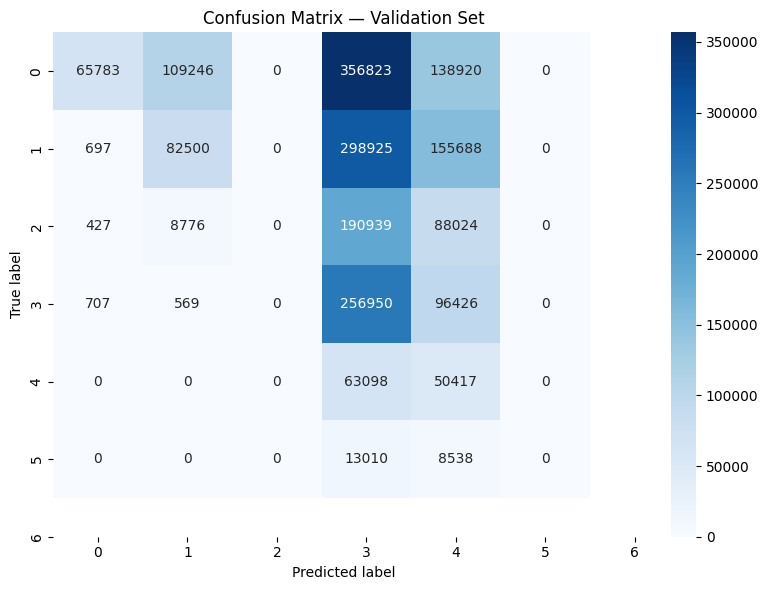

In [84]:
# Confusion matrix
cm = confusion_matrix(all_true_labels, all_proc_preds)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=range(n_classes), yticklabels=range(n_classes))
plt.xlabel("Predicted label")
plt.ylabel("True label")
plt.title("Confusion Matrix — Validation Set")
plt.tight_layout()
plt.show()

## 9. Per-Well Visualisation

In [85]:
import matplotlib.colors as colors

def plot_well_side_by_side(
    df_well, actual_labels, predicted_labels,
    well_name=None, log_col='GR_CLEAN', depth_col='DS_INDEX'
):
    log_vals = np.array(df_well[log_col])
    depth    = np.array(df_well[depth_col])
    actual   = np.array(actual_labels)
    predicted = np.array(predicted_labels)

    n_ticks   = n_classes
    boundaries = np.arange(0.5, n_ticks + 1.5, 1)
    
    # FIX: Use n_classes so colors don't stretch and max out at Cyan
    norm = colors.BoundaryNorm(boundaries, ncolors=n_classes)
    cmap = plt.get_cmap('tab10', n_classes)

    fig, axes = plt.subplots(1, 2, figsize=(12, 8), sharey=True)

    sc1 = axes[0].scatter(log_vals, depth, c=actual, cmap=cmap, s=10, norm=norm)
    axes[0].invert_yaxis()
    axes[0].set_xlabel(log_col)
    axes[0].set_ylabel("Depth (DS_INDEX)")
    axes[0].set_title(f"Actual\n{well_name}" if well_name else "Actual")

    sc2 = axes[1].scatter(log_vals, depth, c=predicted, cmap=cmap, s=10, norm=norm)
    axes[1].invert_yaxis()
    axes[1].set_xlabel(log_col)
    axes[1].set_title("Predicted")

    fig.subplots_adjust(right=0.82)
    cbar_ax = fig.add_axes([0.85, 0.15, 0.03, 0.7])
    cbar = fig.colorbar(sc2, cax=cbar_ax, ticks=list(range(1, n_ticks + 1)))
    cbar.set_label("Marker Label")

    plt.suptitle(f"Well: {well_name}", fontsize=12)
    plt.tight_layout(rect=[0, 0, 0.82, 1])
    plt.show()


In [86]:
def plot_well_from_name(
    well_name, df_log, df_tops, input_features, model,
    depth_col='DS_INDEX', well_col='well_name'
):
    """
    End-to-end: clean → step-function → graph → predict → plot.

    Changes vs. Colorado version
    ----------------------------
    - Uses well_log_cleaning() with DS_INDEX and string well_name.
    - start_depth is derived per-well (minimum DS_INDEX) not fixed at 6000.
    """
    df_wgr = well_log_cleaning(well_name, df_log, input_features, depth_col, well_col)
    df_wgr = df_wgr.dropna(subset=[depth_col])
    if df_wgr.empty:
        print(f"No valid depth data for well {well_name}")
        return

    tops_list = df_tops.loc[well_name].dropna().tolist() if well_name in df_tops.index else []
    start_d   = float(df_wgr[depth_col].min())
    end_d     = float(df_wgr[depth_col].max())
    step_vals = step_function(start_d, end_d, sorted(tops_list))

    graph = create_graph(df_wgr, step_vals, depth_col=depth_col, input_features=input_features)
    graph = dgl.add_self_loop(graph)

    actual_labels = graph.ndata['label'].cpu().numpy()

    model.eval()
    with torch.no_grad():
        preds = model(graph, graph.ndata['features'])
        
        # Pass the raw logits directly to our new function!
        logits = preds.cpu().numpy()
        predicted_labels = post_process_predictions_prob(logits, window_size=11, transition_threshold=0.5)
        
        predicted_labels = predicted_labels + 1   # back to 1-based for display


    plot_well_side_by_side(df_wgr, actual_labels, predicted_labels, well_name=well_name,
                           depth_col=depth_col)

/var/folders/ss/xj7vz6w928x9h7yd27w3_6_w0000gn/T/ipykernel_83375/2518608765.py:38: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 0.82, 1])


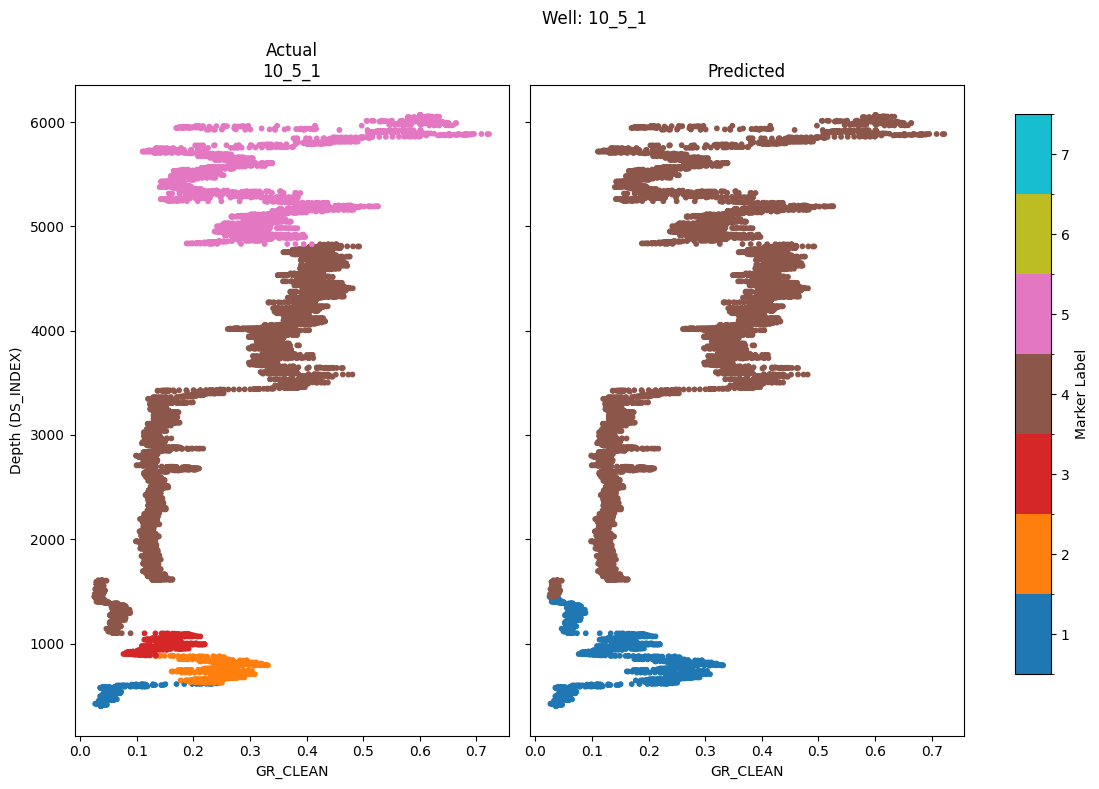

In [87]:
# Example: visualise one validation well
example_well = valid_dataset.well_names[0]
plot_well_from_name(example_well, df_log_valid, df_tops_valid, INPUT_FEATURES, model)

## 10. Predicted Marker Depths & Recall Evaluation

In [48]:
def findIndex(a, n, key):
    """Returns (first_occurrence_index, last_occurrence_index) of key in a."""
    start = -1
    for i in range(n):
        if a[i] == key:
            start = i
            break
    end = start
    if start >= 0:
        for i in range(n - 1, start - 1, -1):
            if a[i] == key:
                end = i
                break
    return (start, end)


def predicted_marker_depths(pred_array, depth_array, n_markers, con='last'):
    """
    Extracts one predicted depth per marker from the prediction array.

    Changes vs. Colorado version
    ----------------------------
    - Generalised to any number of markers (n_markers) instead of hardcoded 3.
    - Returns a dict {marker_index: depth} for easier DataFrame creation.
    - 'first' picks the first index where label == marker_class;
      'last' picks the last index.
    """
    arr = pred_array
    n   = len(arr)
    i   = 0 if con == 'first' else 1

    depths = {}
    for m in range(n_markers):
        label = m + 2   # marker classes start at 2 (1 = background before first marker)
        idx   = findIndex(arr, n, label)
        pos   = idx[i]
        depths[m] = float(depth_array[pos]) if (0 <= pos < len(depth_array)) else np.nan

    return depths

In [49]:
# Generate predictions for all validation wells
n_markers   = len(MARKER_COLS)   # 6
valid_wells = valid_dataset.well_names
records     = []

for idx, well in enumerate(tqdm.tqdm(valid_wells, desc="Predicting")):
    df_wgr = well_log_cleaning(well, df_log_valid, INPUT_FEATURES)
    if df_wgr.empty:
        continue

    tops_list = df_tops_valid.loc[well].dropna().tolist() if well in df_tops_valid.index else []
    start_d   = float(df_wgr['DS_INDEX'].min())
    end_d     = float(df_wgr['DS_INDEX'].max())
    step_vals = step_function(start_d, end_d, sorted(tops_list))

    graph = create_graph(df_wgr, step_vals)
    if graph.num_nodes() == 0:
        continue
    graph = dgl.add_self_loop(graph)

    model.eval()
    with torch.no_grad():
        preds = model(graph, graph.ndata['features']).argmax(dim=1).cpu().numpy()
        preds = post_process_predictions(preds, window_size=5)

    depth_array = [t[0] for t in step_vals]
    pred_depths = predicted_marker_depths(preds, depth_array, n_markers, con='last')

    row = {'well_name': well}
    for m, col in enumerate(MARKER_COLS):
        row[col] = pred_depths[m]
    records.append(row)

df_preds = pd.DataFrame(records).set_index('well_name')
print(df_preds.shape)
df_preds.head()

Predicting:   0%|          | 0/100 [00:00<?, ?it/s]

Predicting: 100%|██████████| 100/100 [00:25<00:00,  3.90it/s]

(100, 6)


,DUNLIN,HORDALAND,ROGALAND,SHETLAND,VESTLAND,VIKING
well_name,,,,,,
10_5_1,5489.1601,6068.1601,6056.6601,5752.1601,NaN,NaN
15_12_12,8580.6601,10111.1601,10115.1601,NaN,NaN,NaN
15_3_2,13236.1601,15518.6601,15597.1601,14738.6601,NaN,NaN
15_3_5,12238.1601,13602.1601,13377.6601,13358.1601,NaN,NaN
15_5_5,8476.1601,8678.1601,8604.6601,NaN,NaN,NaN


In [50]:
def recall_tops(df_tops_true, df_tops_pred, tolerance=10):
    """Unchanged from Colorado version."""
    if set(df_tops_true.columns) != set(df_tops_pred.columns):
        print("Column mismatch:", df_tops_true.columns.tolist(), "vs", df_tops_pred.columns.tolist())
        return None, None, None

    concat_df = df_tops_true.copy()
    for col in df_tops_pred.columns:
        concat_df[col + "_pred"] = df_tops_pred[col]

    tp, p, mae = 0, 0, 0
    for col in df_tops_true.columns:
        p   += concat_df[col].count()
        diff = (concat_df[col] - concat_df[col + "_pred"]).abs()
        tp  += (diff <= tolerance).sum()
        mae += diff.sum()

    return tp / p, mae / p, concat_df

In [51]:
# Align actual tops to predicted wells
df_tops_actual = df_tops_valid.loc[
    df_tops_valid.index.isin(df_preds.index)
].copy()
df_tops_actual = df_tops_actual.reindex(df_preds.index)

recall, mae, df_results = recall_tops(df_tops_actual, df_preds, tolerance=20)
print(f"Recall (±20 ft): {recall:.4f}   MAE: {mae:.2f} ft")
df_results.head()

Recall (±20 ft): 0.0030   MAE: 3270.99 ft


valid_marker_name,DUNLIN,HORDALAND,ROGALAND,SHETLAND,VESTLAND,VIKING,DUNLIN_pred,HORDALAND_pred,ROGALAND_pred,SHETLAND_pred,VESTLAND_pred,VIKING_pred
well_name,,,,,,,,,,,,
10_5_1,NaN,623.35960,885.82680,1099.08140,4829.39648,NaN,5489.1601,6068.1601,6056.6601,5752.1601,NaN,NaN
15_12_12,NaN,4084.64580,7342.51992,8021.65380,NaN,9163.38612,8580.6601,10111.1601,10115.1601,NaN,NaN,NaN
15_3_2,NaN,2198.16280,6830.70888,8818.89792,NaN,13897.63824,13236.1601,15518.6601,15597.1601,14738.6601,NaN,NaN
15_3_5,NaN,3044.61952,NaN,9196.19452,12910.10540,12493.43872,12238.1601,13602.1601,13377.6601,13358.1601,NaN,NaN
15_5_5,NaN,2929.79012,6650.26268,8523.62232,NaN,NaN,8476.1601,8678.1601,8604.6601,NaN,NaN,NaN


## 11. Learning Curve

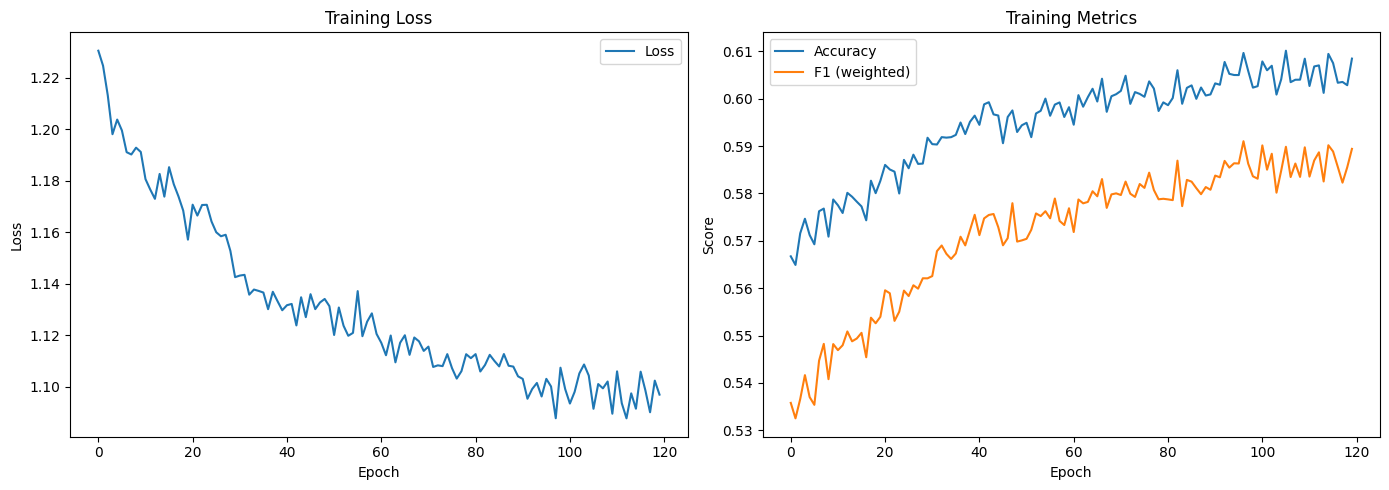

In [52]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(loss_hist, label='Loss')
axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Loss")
axes[0].set_title("Training Loss")
axes[0].legend()

axes[1].plot(acc_hist,  label='Accuracy')
axes[1].plot(f1_hist,   label='F1 (weighted)')
axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Score")
axes[1].set_title("Training Metrics")
axes[1].legend()

plt.tight_layout()
plt.show()

## 12. Multi-Model Sweep with Carbon Tracking

Run all four architectures (ImprovedGNN, ExtendedGAT, GraphSAGE, ExtendedGraphSAGE) with:
- Learning rate: 0.005
- Epochs: 15 (capped for presentation)
- Carbon emissions measured via CodeCarbon

In [ ]:

# ── GraphSAGE architectures ────────────────────────────────────────────────

class GraphSAGE(nn.Module):
    """Three-layer SAGEConv with mean aggregation, BatchNorm, and Dropout."""
    def __init__(self, in_feats, h_feats, num_classes, dropout=0.1):
        super(GraphSAGE, self).__init__()
        self.conv1 = dglnn.SAGEConv(in_feats,  h_feats, 'mean')
        self.conv2 = dglnn.SAGEConv(h_feats,   h_feats, 'mean')
        self.conv3 = dglnn.SAGEConv(h_feats,   h_feats, 'mean')
        self.bn1   = nn.BatchNorm1d(h_feats)
        self.bn2   = nn.BatchNorm1d(h_feats)
        self.bn3   = nn.BatchNorm1d(h_feats)
        self.dropout = nn.Dropout(dropout)
        self.fc    = nn.Linear(h_feats, num_classes)

    def forward(self, g, x):
        h = F.relu(self.bn1(self.conv1(g, x)));  h = self.dropout(h)
        h = F.relu(self.bn2(self.conv2(g, h)));  h = self.dropout(h)
        h = F.relu(self.bn3(self.conv3(g, h)));  h = self.dropout(h)
        return self.fc(h)


class ExtendedGraphSAGE(nn.Module):
    """Deeper SAGEConv stack (5 layers) with residual-style skip from layer 2→4."""
    def __init__(self, in_feats, h_feats, num_classes, dropout=0.1):
        super(ExtendedGraphSAGE, self).__init__()
        self.convs = nn.ModuleList([
            dglnn.SAGEConv(in_feats, h_feats, 'mean'),
            dglnn.SAGEConv(h_feats,  h_feats, 'mean'),
            dglnn.SAGEConv(h_feats,  h_feats, 'mean'),
            dglnn.SAGEConv(h_feats,  h_feats, 'mean'),
            dglnn.SAGEConv(h_feats,  h_feats, 'mean'),
        ])
        self.bns = nn.ModuleList([nn.BatchNorm1d(h_feats) for _ in range(5)])
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(h_feats, num_classes)

    def forward(self, g, x):
        h = x
        skip = None
        for i, (conv, bn) in enumerate(zip(self.convs, self.bns)):
            h_new = F.relu(bn(conv(g, h)))
            h_new = self.dropout(h_new)
            if i == 1:
                skip = h_new
            if i == 3 and skip is not None:
                h_new = h_new + skip
            h = h_new
        return self.fc(h)

print("GraphSAGE and ExtendedGraphSAGE defined.")


In [ ]:

import warnings, time
warnings.filterwarnings("ignore", message="TypedStorage is deprecated", category=UserWarning)

from codecarbon import EmissionsTracker

# ── Shared hyper-parameters ────────────────────────────────────────────────
SWEEP_LR     = 0.005
SWEEP_EPOCHS = 15
H_FEATS      = 128

supports = torch.tensor([1000, 800, 600, 500, 400, 300, 200], dtype=torch.float32)
sweep_weights = supports.max() / supports
sweep_criterion = nn.CrossEntropyLoss(weight=sweep_weights)

in_feats   = len(INPUT_FEATURES)
n_cls      = N_CLASSES

# ── Factory: (name → model instance) ──────────────────────────────────────
def make_model(name):
    if name == 'ImprovedGNN':
        return ImprovedGNN(in_feats, [128, 256, 256, 128, 64], n_cls, dropout=0.1)
    if name == 'ExtendedGAT':
        return ExtendedGAT(in_feats, h_feats=64, num_classes=n_cls, num_heads=4, dropout=0.1)
    if name == 'GraphSAGE':
        return GraphSAGE(in_feats, H_FEATS, n_cls, dropout=0.1)
    if name == 'ExtendedGraphSAGE':
        return ExtendedGraphSAGE(in_feats, H_FEATS, n_cls, dropout=0.1)
    raise ValueError(f"Unknown model: {name}")

MODEL_NAMES = ['ImprovedGNN', 'ExtendedGAT', 'GraphSAGE', 'ExtendedGraphSAGE']
sweep_results = {}

for model_name in MODEL_NAMES:
    print(f"\n{'='*60}")
    print(f"  Model: {model_name}  |  lr={SWEEP_LR}  |  epochs={SWEEP_EPOCHS}")
    print(f"{'='*60}")

    m = make_model(model_name)
    opt = torch.optim.Adam(m.parameters(), lr=SWEEP_LR)
    sch = torch.optim.lr_scheduler.StepLR(opt, step_size=10, gamma=0.5)

    tracker = EmissionsTracker(
        project_name=f"GNN_NorthSea_{model_name}",
        output_dir="/tmp",
        log_level="error",
        save_to_file=False,
    )
    tracker.start()
    t0 = time.time()

    loss_h, acc_h, f1_h = train_gnn(
        m, train_dataloader, opt, sweep_criterion, sch,
        n_classes=n_cls, epochs=SWEEP_EPOCHS
    )

    emissions_kg = tracker.stop()           # kg CO₂eq
    elapsed      = time.time() - t0

    # ── Validation ──────────────────────────────────────────────────────────
    m.eval()
    all_preds_v, all_labels_v = [], []
    with torch.no_grad():
        for batch in valid_dataloader:
            if batch.num_nodes() == 0:
                continue
            batch = dgl.add_self_loop(batch)
            logits = m(batch, batch.ndata['features']).cpu().numpy()
            labels = batch.ndata['label'].cpu().numpy()
            labels_adj = np.clip(labels - 1, 0, n_cls - 1)
            all_preds_v.extend(logits.argmax(axis=1))
            all_labels_v.extend(labels_adj)

    v_acc = accuracy_score(all_labels_v, all_preds_v)
    v_f1  = f1_score(all_labels_v, all_preds_v, average='weighted', zero_division=0)
    v_p   = precision_score(all_labels_v, all_preds_v, average='weighted', zero_division=0)
    v_r   = recall_score(all_labels_v, all_preds_v, average='weighted', zero_division=0)

    sweep_results[model_name] = {
        'loss_hist': loss_h,
        'acc_hist':  acc_h,
        'f1_hist':   f1_h,
        'val_acc':   v_acc,
        'val_f1':    v_f1,
        'val_prec':  v_p,
        'val_rec':   v_r,
        'train_time_s':     elapsed,
        'emissions_kg_co2': emissions_kg if emissions_kg else 0.0,
    }

    print(f"\n  Val Acc: {v_acc:.4f}  F1: {v_f1:.4f}  P: {v_p:.4f}  R: {v_r:.4f}")
    print(f"  Train time: {elapsed:.1f}s  |  CO₂: {(emissions_kg or 0)*1000:.4f} g")

print("\n\nSweep complete.")


In [ ]:

# ── Summary table ─────────────────────────────────────────────────────────
rows = []
for name, r in sweep_results.items():
    rows.append({
        'Model':          name,
        'Val Acc':        round(r['val_acc'],  4),
        'Val F1':         round(r['val_f1'],   4),
        'Val Precision':  round(r['val_prec'], 4),
        'Val Recall':     round(r['val_rec'],  4),
        'Train time (s)': round(r['train_time_s'], 1),
        'CO₂ (g)':        round(r['emissions_kg_co2'] * 1000, 5),
    })

df_summary = pd.DataFrame(rows).set_index('Model')
print(df_summary.to_string())
df_summary


In [ ]:

# ── Comparison plots ───────────────────────────────────────────────────────
colors_map = {'ImprovedGNN': '#1f77b4', 'ExtendedGAT': '#ff7f0e',
              'GraphSAGE': '#2ca02c', 'ExtendedGraphSAGE': '#d62728'}

fig, axes = plt.subplots(2, 3, figsize=(18, 10))

# 1. Training loss curves
ax = axes[0, 0]
for name, r in sweep_results.items():
    ax.plot(r['loss_hist'], label=name, color=colors_map[name])
ax.set_title("Training Loss"); ax.set_xlabel("Epoch"); ax.set_ylabel("Loss")
ax.legend(fontsize=8); ax.grid(alpha=0.3)

# 2. Training accuracy curves
ax = axes[0, 1]
for name, r in sweep_results.items():
    ax.plot(r['acc_hist'], label=name, color=colors_map[name])
ax.set_title("Training Accuracy"); ax.set_xlabel("Epoch"); ax.set_ylabel("Accuracy")
ax.legend(fontsize=8); ax.grid(alpha=0.3)

# 3. Training F1 curves
ax = axes[0, 2]
for name, r in sweep_results.items():
    ax.plot(r['f1_hist'], label=name, color=colors_map[name])
ax.set_title("Training F1 (weighted)"); ax.set_xlabel("Epoch"); ax.set_ylabel("F1")
ax.legend(fontsize=8); ax.grid(alpha=0.3)

# 4. Validation bar — Accuracy & F1
ax = axes[1, 0]
x = np.arange(len(MODEL_NAMES)); w = 0.35
acc_vals = [sweep_results[n]['val_acc'] for n in MODEL_NAMES]
f1_vals  = [sweep_results[n]['val_f1']  for n in MODEL_NAMES]
ax.bar(x - w/2, acc_vals, w, label='Val Acc', color=[colors_map[n] for n in MODEL_NAMES], alpha=0.7)
ax.bar(x + w/2, f1_vals,  w, label='Val F1',  color=[colors_map[n] for n in MODEL_NAMES], alpha=0.4, edgecolor='k', linewidth=0.8)
ax.set_xticks(x); ax.set_xticklabels(MODEL_NAMES, rotation=15, ha='right', fontsize=8)
ax.set_title("Validation Accuracy & F1"); ax.set_ylabel("Score")
ax.legend(); ax.grid(axis='y', alpha=0.3)

# 5. Training time
ax = axes[1, 1]
times = [sweep_results[n]['train_time_s'] for n in MODEL_NAMES]
bars = ax.bar(MODEL_NAMES, times, color=[colors_map[n] for n in MODEL_NAMES], alpha=0.8)
ax.set_title("Training Time (s)"); ax.set_ylabel("Seconds")
ax.set_xticklabels(MODEL_NAMES, rotation=15, ha='right', fontsize=8)
for b, t in zip(bars, times):
    ax.text(b.get_x() + b.get_width()/2, b.get_height() + 1, f'{t:.0f}s', ha='center', fontsize=8)
ax.grid(axis='y', alpha=0.3)

# 6. Carbon emissions
ax = axes[1, 2]
co2_vals = [sweep_results[n]['emissions_kg_co2'] * 1000 for n in MODEL_NAMES]
bars = ax.bar(MODEL_NAMES, co2_vals, color=[colors_map[n] for n in MODEL_NAMES], alpha=0.8)
ax.set_title("CO₂ Emissions (g CO₂eq)"); ax.set_ylabel("grams CO₂eq")
ax.set_xticklabels(MODEL_NAMES, rotation=15, ha='right', fontsize=8)
for b, v in zip(bars, co2_vals):
    ax.text(b.get_x() + b.get_width()/2, b.get_height(), f'{v:.4f}g', ha='center', va='bottom', fontsize=7)
ax.grid(axis='y', alpha=0.3)

plt.suptitle("GNN Architecture Comparison — North Sea (15 epochs, lr=0.005)", fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig("gnn_sweep_comparison.png", dpi=150, bbox_inches='tight')
plt.show()
print("Figure saved to gnn_sweep_comparison.png")
